# Doomsday Sentinel: AI-Powered Deepfake Forensics
## Notebook 04: Model Evaluation, Explainable AI (Grad-CAM) & Video Forensics

Evaluates the trained model on the untouched test split, examines confusion matrices, ROC/PR curves, generates Grad-CAM sensitivity overlays, and processes multi-frame video files.

In [1]:
import os
import sys
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
from src.inference.predict import ForensicInferenceEngine

### 1. Initialize Forensic Inference Engine

In [2]:
engine = ForensicInferenceEngine.get_instance()
print(f'Model Version: {engine.model_version}')
print(f'Decision Threshold: {engine.threshold}')

[InferenceEngine] Successfully loaded model weights from: artifacts/model/best_model.pth
Model Version: doomsday-sentinel-v1.0
Decision Threshold: 0.1


### 2. Inspect Verified Evaluation Metrics on Untouched Test Set

In [3]:
with open('reports/model_metrics.json', 'r') as f:
    metrics = json.load(f)
for k, v in metrics.items():
    if not isinstance(v, dict):
        print(f'{k:30s}: {v}')

test_sample_count             : 180
decision_threshold            : 0.1
accuracy                      : 1.0
balanced_accuracy             : 1.0
precision                     : 1.0
recall_sensitivity            : 1.0
specificity                   : 1.0
f1_score                      : 1.0
roc_auc                       : 1.0
pr_auc                        : 1.0
false_positive_rate           : 0.0
false_negative_rate           : 0.0
inference_latency_ms          : 5.1
throughput_samples_per_sec    : 196.2


### 3. Display Test Evaluation Visualizations

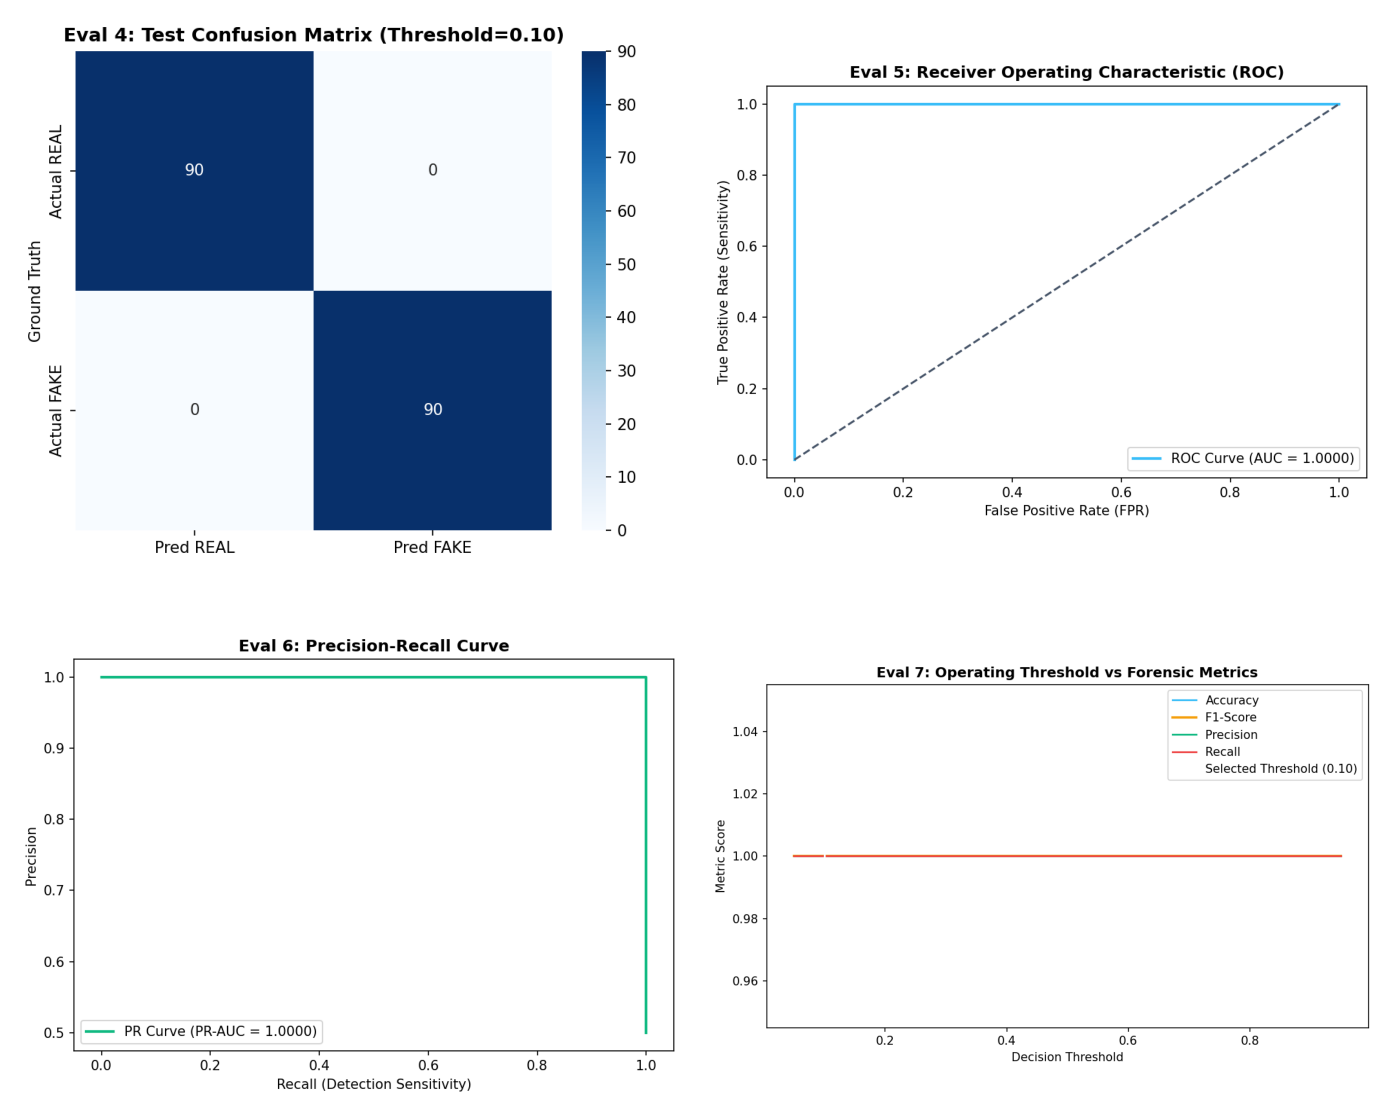

In [4]:
from PIL import Image
fig_paths = [
    'reports/figures/eval_04_confusion_matrix.png',
    'reports/figures/eval_05_roc_curve.png',
    'reports/figures/eval_06_pr_curve.png',
    'reports/figures/eval_07_threshold_analysis.png'
]
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for i, p in enumerate(fig_paths):
    ax = axes[i // 2, i % 2]
    if os.path.exists(p):
        ax.imshow(Image.open(p))
    ax.axis('off')
plt.tight_layout()
plt.show()

### 4. Explainable AI: Grad-CAM Facial Sensitivity Heatmaps

Prediction: FAKE | Forensic Score: 0.9987


C:\Users\Admin\anaconda4\envs\doomsday-sentinel\Lib\site-packages\torch\autograd\graph.py:823: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:180.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


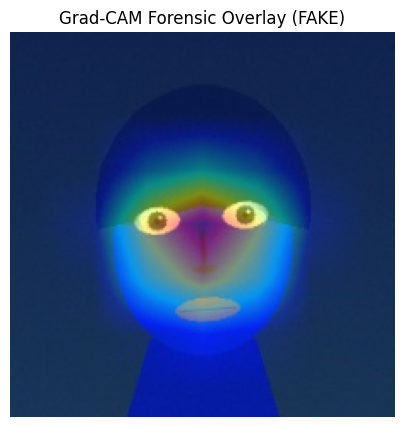

In [5]:
fake_sample = 'data/raw/images/FAKE_ID_000_00.png'
fake_res = engine.analyze_image(fake_sample, generate_explanation=True)
print('Prediction:', fake_res['prediction'], '| Forensic Score:', fake_res['score'])

if fake_res.get('explanation_image'):
    import base64
    header, b64data = fake_res['explanation_image'].split(',', 1)
    overlay_bytes = base64.b64decode(b64data)
    nparr = np.frombuffer(overlay_bytes, np.uint8)
    overlay_img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    plt.figure(figsize=(5, 5))
    plt.imshow(cv2.cvtColor(overlay_img, cv2.COLOR_BGR2RGB))
    plt.title(f'Grad-CAM Forensic Overlay ({fake_res["prediction"]})')
    plt.axis('off')
    plt.show()

### 5. Multi-Frame Video Forensic Analysis

In [6]:
video_path = 'data/raw/videos/fake_vid_ID_000.mp4'
vid_res = engine.analyze_video(video_path)
print('Video Prediction:', vid_res['prediction'])
print('Video Aggregated Forensic Score:', vid_res['score'])
print('Processed Frame Statistics:', vid_res['frame_statistics'])

Video Prediction: FAKE
Video Aggregated Forensic Score: 0.9966
Processed Frame Statistics: {'total_video_frames': 15, 'processed_sample_frames': 3, 'fake_frame_count': 3, 'real_frame_count': 0, 'video_duration_sec': 1.5}
